In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/spam.csv", encoding="latin-1")
df = df[["v1", "v2"]]
df.columns = ["label", "message"]
df = df.drop_duplicates()
df["length"] = df["message"].apply(len)
print(df.shape)

(5169, 3)


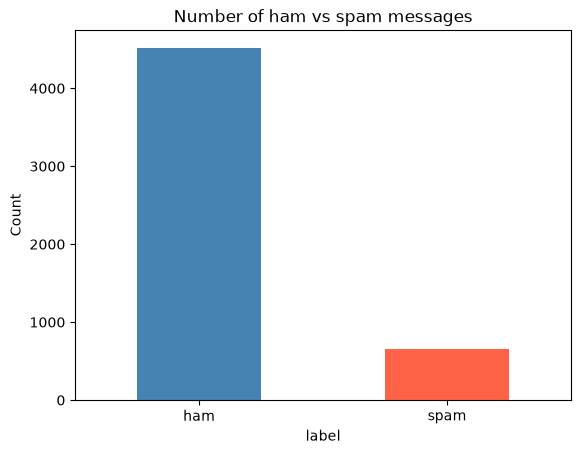

In [2]:
df["label"].value_counts().plot(kind="bar", color=["steelblue", "tomato"])
plt.title("Number of ham vs spam messages")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

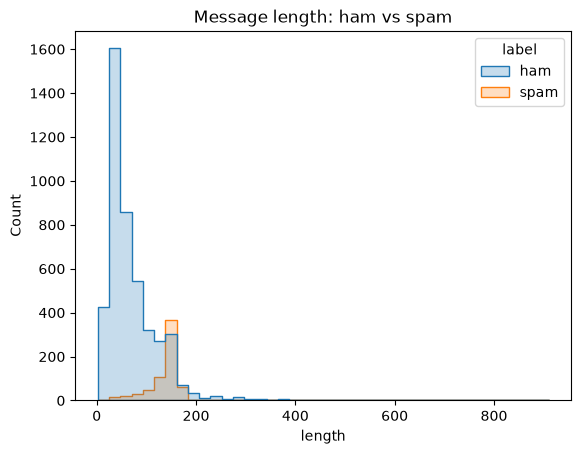

In [3]:
sns.histplot(data=df, x="length", hue="label", bins=40, element="step")
plt.title("Message length: ham vs spam")
plt.show()

In [4]:
df["digits"] = df["message"].apply(lambda t: sum(c.isdigit() for c in t))
df["capitals"] = df["message"].apply(lambda t: sum(c.isupper() for c in t))
df["words"] = df["message"].apply(lambda t: len(t.split()))

df.groupby("label")[["length", "digits", "capitals", "words"]].mean()

,length,digits,capitals,words
label,,,,
ham,70.459256,0.290301,3.904119,14.134632
spam,137.891271,15.447167,15.246554,23.681470


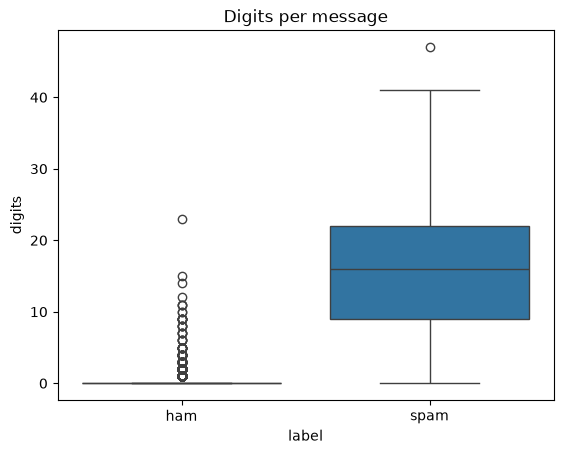

In [5]:
sns.boxplot(data=df, x="label", y="digits")
plt.title("Digits per message")
plt.show()

In [6]:
import re
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def top_words(label, n=15):
    words = []
    for msg in df[df["label"] == label]["message"]:
        for w in re.findall(r"[a-z]+", msg.lower()):
            if w not in ENGLISH_STOP_WORDS and len(w) > 2:
                words.append(w)
    return Counter(words).most_common(n)

print("SPAM:", top_words("spam"))
print()
print("HAM:", top_words("ham"))

SPAM: [('free', 197), ('txt', 141), ('stop', 114), ('mobile', 111), ('text', 109), ('claim', 96), ('reply', 96), ('www', 83), ('prize', 82), ('just', 67), ('cash', 65), ('new', 64), ('won', 61), ('send', 59), ('nokia', 59)]

HAM: [('just', 278), ('got', 227), ('know', 225), ('like', 222), ('good', 215), ('come', 212), ('time', 192), ('day', 189), ('love', 180), ('going', 164), ('want', 161), ('lor', 159), ('home', 156), ('need', 154), ('don', 149)]


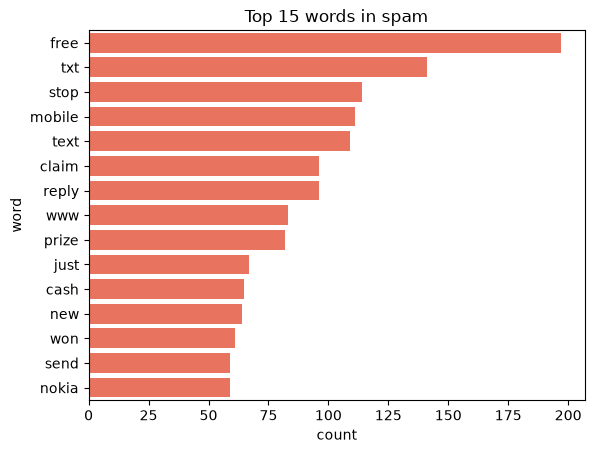

In [7]:
spam_words = pd.DataFrame(top_words("spam"), columns=["word", "count"])
sns.barplot(data=spam_words, x="count", y="word", color="tomato")
plt.title("Top 15 words in spam")
plt.show()